**PÓS-GRADUAÇÃO · DATA SCIENCE & BIG DATA APLICADOS NA INDÚSTRIA**

# Aula 06 · Exercício 03
## Evolução dos preços de fechamento de ações

| Identificação | Dados |
| :--- | :--- |
| **Aluno** | Carlos Alexandre Duarte Pereira |
| **Curso** | Data Science & Big Data Aplicados na Indústria |
| **Disciplina** | Python para Data Science |
| **Professor** | Me. Daniel Vieira |
| **Data** | 13/11/2026 |

---

**Tema:** série de preços com Pandas, gráfico de linhas e cálculo de resultado de uma operação.


## Enunciado e execução

Organizar os preços de fechamento de uma companhia durante dez dias e construir um gráfico de linhas para identificar períodos de valorização e desvalorização. Os valores são os dados didáticos fornecidos no exercício.

Os dados são os mesmos do PDF **Aula 01 — Python para Data Science**, páginas 43 a 45.
A pasta `Aula06` acompanha a sequência do repositório; o PDF corresponde à primeira aula desta disciplina.

No Jupyter ou VS Code, selecione um ambiente Python com Pandas e Matplotlib e execute as células em ordem.
No Google Colab, use **Ambiente de execução → Executar tudo**. Os dados estão incorporados ao notebook.
As orientações para criar e ativar o ambiente virtual e executar a versão `.py` estão no `README.md` desta pasta.


In [1]:
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


In [2]:
# 2. CRIAÇÃO DO DATAFRAME
dados = {
    "dia": ["D1", "D2", "D3", "D4", "D5",
            "D6", "D7", "D8", "D9", "D10"],
    "preco": [25.50, 26.20, 25.80, 27.00, 28.50,
              27.80, 29.20, 30.50, 29.80, 31.00]
}
df = pd.DataFrame(dados)
display(df)


,dia,preco
0,D1,25.5
1,D2,26.2
2,D3,25.8
3,D4,27.0
4,D5,28.5
5,D6,27.8
6,D7,29.2
7,D8,30.5
8,D9,29.8
9,D10,31.0


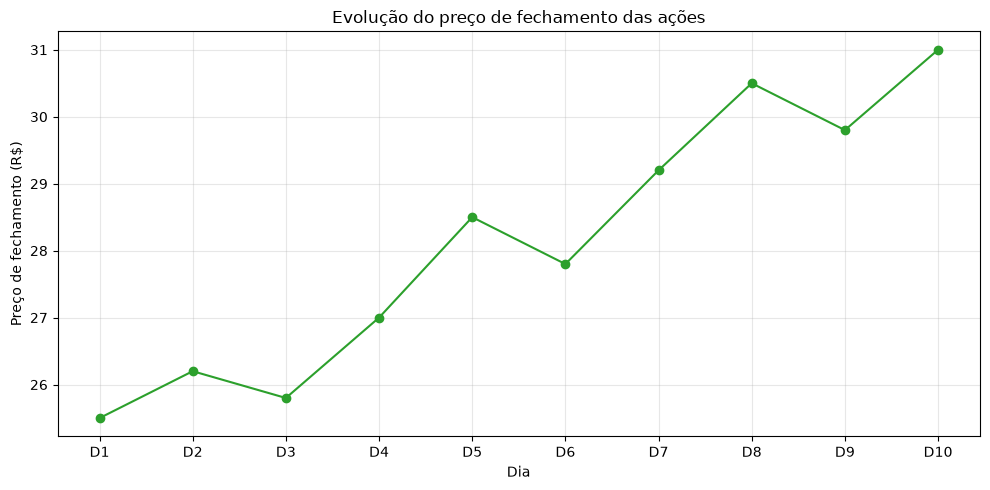

In [3]:
# 3. GRÁFICO DE LINHAS
# Mantém a ordem D1 a D10 fornecida no enunciado.
plt.figure(figsize=(10, 5))
plt.plot(df["dia"], df["preco"], marker="o", color="tab:green")
plt.title("Evolução do preço de fechamento das ações")
plt.xlabel("Dia")
plt.ylabel("Preço de fechamento (R$)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Questões para análise


### a) Qual foi o maior preço registrado durante os 10 dias?


In [4]:
maior_preco = df["preco"].max()
display(df.loc[df["preco"] == maior_preco, ["dia", "preco"]])


,dia,preco
9,D10,31.0


O maior preço de fechamento foi de **R$ 31,00**, no **D10**.


### b) Qual foi o menor preço registrado?


In [5]:
menor_preco = df["preco"].min()
display(df.loc[df["preco"] == menor_preco, ["dia", "preco"]])


,dia,preco
0,D1,25.5


O menor preço de fechamento foi de **R$ 25,50**, no **D1**.


### c) Em quais dias ocorreram quedas no preço das ações?


In [6]:
# Compara o preço de cada dia com o do dia anterior.
df["variacao_preco"] = df["preco"].diff().round(2)
quedas = df.loc[df["variacao_preco"] < 0, ["dia", "preco", "variacao_preco"]]
display(quedas)


,dia,preco,variacao_preco
2,D3,25.8,-0.4
5,D6,27.8,-0.7
8,D9,29.8,-0.7


As quedas ocorreram no **D3, D6 e D9**, em relação ao dia anterior. As reduções foram de **R$ 0,40**, **R$ 0,70** e **R$ 0,70**, respectivamente. O D1 não possui um dia anterior na base para comparação.


### d) Qual foi a média dos preços de fechamento?


In [7]:
preco_medio = df["preco"].mean()
print("Preço médio: R$", f"{preco_medio:.2f}".replace(".", ","))


Preço médio: R$ 28,13


A média dos dez preços de fechamento foi de **R$ 28,13**.


### e) Se um investidor comprou 100 ações no primeiro dia e vendeu todas no último dia, qual seria o lucro obtido, desconsiderando taxas e impostos?


In [8]:
quantidade_acoes = 100
preco_compra = df["preco"].iloc[0]
preco_venda = df["preco"].iloc[-1]
valor_compra = quantidade_acoes * preco_compra
valor_venda = quantidade_acoes * preco_venda
lucro = valor_venda - valor_compra
display(pd.DataFrame({
    "descricao": ["Compra de 100 ações no D1", "Venda de 100 ações no D10", "Lucro bruto"],
    "valor_rs": [valor_compra, valor_venda, lucro]
}))


,descricao,valor_rs
0,Compra de 100 ações no D1,2550.0
1,Venda de 100 ações no D10,3100.0
2,Lucro bruto,550.0


A compra custaria **100 × R$ 25,50 = R$ 2.550,00**. A venda renderia **100 × R$ 31,00 = R$ 3.100,00**. O lucro seria de **R$ 550,00**, desconsiderando taxas e impostos, conforme o enunciado.


## Conclusão

O preço passou de R$ 25,50 no primeiro dia para R$ 31,00 no último. Apesar da valorização no período, houve três quedas entre dias consecutivos. A simulação de compra e venda resultou em lucro bruto de R$ 550,00 para 100 ações nos preços informados.


## Material utilizado

VIEIRA, Daniel. *Aula 01 — Python para Data Science*. Material da disciplina, páginas 43 a 45.
Arquivo original: [Aula 01 - Python para Data Science.pdf](Aula%2001%20-%20Python%20para%20Data%20Science.pdf).
